In [1]:
# Stage 01

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torchvision import datasets, transforms

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
!wget -q https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip

In [4]:
!unzip -q EuroSAT_RGB.zip

In [5]:
!ls

EuroSAT_RGB  EuroSAT_RGB.zip  sample_data


In [6]:
dataset_path = "/content/EuroSAT_RGB"

print(os.listdir(dataset_path))

['Highway', 'HerbaceousVegetation', 'River', 'Residential', 'PermanentCrop', 'Industrial', 'Pasture', 'AnnualCrop', 'Forest', 'SeaLake']


In [7]:
classes = sorted(os.listdir(dataset_path))

print("Number of classes:", len(classes))
print("\nClasses:")

for i, class_name in enumerate(classes):
    print(i, "→", class_name)

Number of classes: 10

Classes:
0 → AnnualCrop
1 → Forest
2 → HerbaceousVegetation
3 → Highway
4 → Industrial
5 → Pasture
6 → PermanentCrop
7 → Residential
8 → River
9 → SeaLake


In [8]:
class_counts = {}

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    class_counts[class_name] = len(os.listdir(class_path))

class_counts

{'AnnualCrop': 3000,
 'Forest': 3000,
 'HerbaceousVegetation': 3000,
 'Highway': 2500,
 'Industrial': 2500,
 'Pasture': 2000,
 'PermanentCrop': 2500,
 'Residential': 3000,
 'River': 2500,
 'SeaLake': 3000}

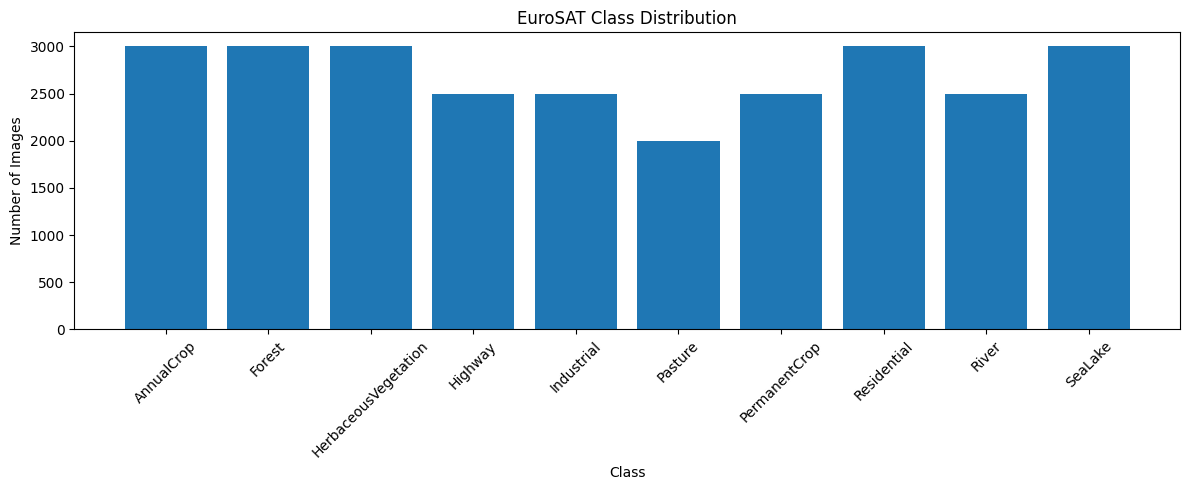

In [9]:
plt.figure(figsize=(12, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.xticks(rotation=45)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("EuroSAT Class Distribution")

plt.tight_layout()
plt.show()

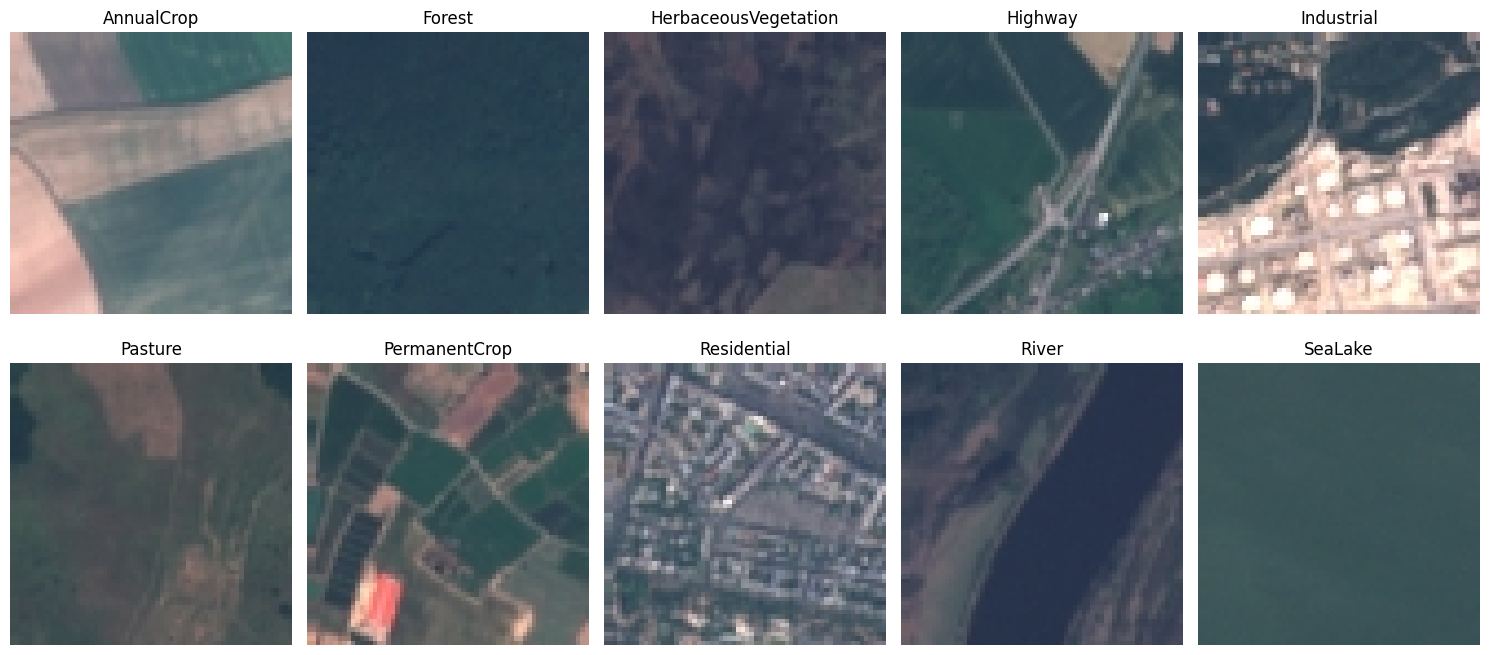

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, class_name in zip(axes.flatten(), classes):

    class_path = os.path.join(dataset_path, class_name)

    image_name = random.choice(os.listdir(class_path))

    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
sample_class = classes[0]

sample_class_path = os.path.join(dataset_path, sample_class)

sample_image_name = os.listdir(sample_class_path)[0]

sample_image_path = os.path.join(
    sample_class_path,
    sample_image_name
)

image = Image.open(sample_image_path)

print("Image:", sample_image_name)
print("Size:", image.size)
print("Mode:", image.mode)

Image: AnnualCrop_1829.jpg
Size: (64, 64)
Mode: RGB


In [12]:
transform = transforms.ToTensor()

image_tensor = transform(image)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("Minimum value:", image_tensor.min())
print("Maximum value:", image_tensor.max())

Tensor shape: torch.Size([3, 64, 64])
Tensor dtype: torch.float32
Minimum value: tensor(0.3490)
Maximum value: tensor(1.)


In [13]:
transform = transforms.ToTensor()

dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=transform
)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)

Total images: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Class mapping: {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


In [14]:
{
    'AnnualCrop': 0,
    'Forest': 1,
    'HerbaceousVegetation': 2,
    'Highway': 3,
    'Industrial': 4,
    'Pasture': 5,
    'PermanentCrop': 6,
    'Residential': 7,
    'River': 8,
    'SeaLake': 9
}

{'AnnualCrop': 0,
 'Forest': 1,
 'HerbaceousVegetation': 2,
 'Highway': 3,
 'Industrial': 4,
 'Pasture': 5,
 'PermanentCrop': 6,
 'Residential': 7,
 'River': 8,
 'SeaLake': 9}

In [15]:
image_tensor, label = dataset[0]

print("Image shape:", image_tensor.shape)
print("Label:", label)
print("Class:", dataset.classes[label])

Image shape: torch.Size([3, 64, 64])
Label: 0
Class: AnnualCrop


In [16]:
from torch.utils.data import random_split

total_size = len(dataset)

train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("Total:", total_size)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Total: 27000
Training: 18900
Validation: 4050
Testing: 4050


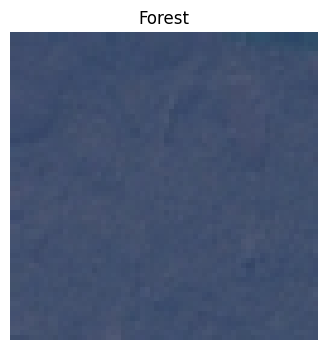

In [17]:
image, label = train_dataset[0]

plt.figure(figsize=(4, 4))

plt.imshow(image.permute(1, 2, 0))

plt.title(dataset.classes[label])
plt.axis("off")

plt.show()

In [18]:
# Stage 02
from torchvision import transforms

In [19]:
transforms.Resize((64, 64))

Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)

In [20]:
transforms.ToTensor()

ToTensor()

In [21]:
mean = [0.5, 0.5, 0.5]
std  = [0.5, 0.5, 0.5]

In [22]:
transforms.Normalize(
    mean=[0.5, 0.5, 0.5],
    std=[0.5, 0.5, 0.5]
)

Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])

In [23]:
transforms.RandomHorizontalFlip(p=0.5)

RandomHorizontalFlip(p=0.5)

In [24]:
transforms.RandomRotation(10)

RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)

In [25]:
transforms.RandomResizedCrop(
    64,
    scale=(0.8, 1.0)
)

RandomResizedCrop(size=(64, 64), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)

In [26]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(10),

    transforms.RandomResizedCrop(
        64,
        scale=(0.8, 1.0)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [27]:
val_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [28]:
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [29]:
train_full = datasets.ImageFolder(
    root=dataset_path,
    transform=train_transform
)

val_full = datasets.ImageFolder(
    root=dataset_path,
    transform=val_transform
)

test_full = datasets.ImageFolder(
    root=dataset_path,
    transform=test_transform
)

In [30]:
total_size = len(train_full)

train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    total_size,
    generator=generator
).tolist()

train_indices = indices[:train_size]

val_indices = indices[
    train_size:train_size + val_size
]

test_indices = indices[
    train_size + val_size:
]

In [31]:
print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

Train: 18900
Validation: 4050
Test: 4050


In [32]:
from torch.utils.data import Subset

train_dataset = Subset(
    train_full,
    train_indices
)

val_dataset = Subset(
    val_full,
    val_indices
)

test_dataset = Subset(
    test_full,
    test_indices
)

In [33]:
image, label = train_dataset[0]

print("Shape:", image.shape)
print("Label:", label)

Shape: torch.Size([3, 64, 64])
Label: 1


In [34]:
print("Minimum:", image.min().item())
print("Maximum:", image.max().item())
print("Mean:", image.mean().item())

Minimum: -1.0
Maximum: -0.09019607305526733
Mean: -0.33914104104042053


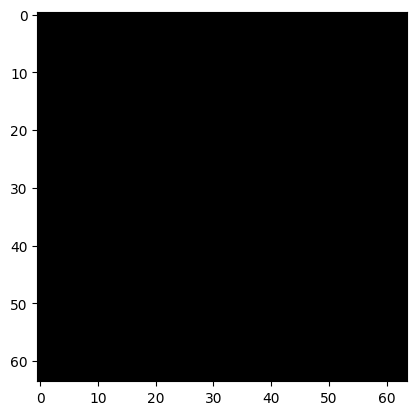

In [35]:
plt.imshow(image.permute(1, 2, 0))

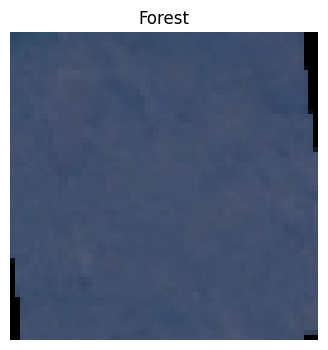

In [36]:
image, label = train_dataset[0]

image = image * 0.5 + 0.5

plt.figure(figsize=(4, 4))

plt.imshow(image.permute(1, 2, 0).clamp(0, 1))

plt.title(dataset.classes[label])

plt.axis("off")

plt.show()

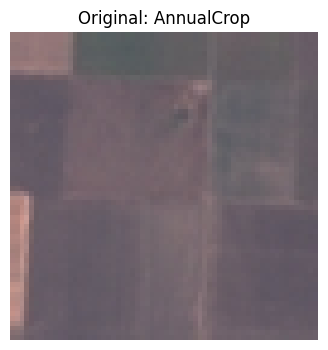

In [37]:
original_dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=transforms.ToTensor()
)

image, label = original_dataset[0]

plt.figure(figsize=(4, 4))

plt.imshow(image.permute(1, 2, 0))

plt.title(
    f"Original: {original_dataset.classes[label]}"
)

plt.axis("off")

plt.show()

In [38]:
augmentation_only = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(
        64,
        scale=(0.8, 1.0)
    )
])

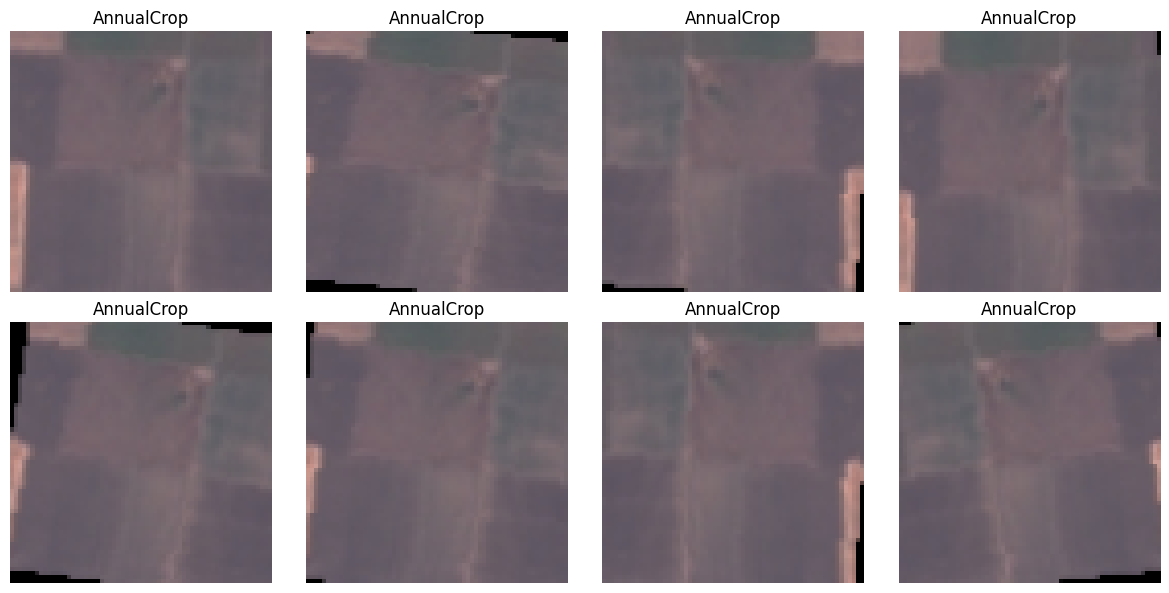

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax in axes.flatten():

    augmented = augmentation_only(image)

    # Convert [C, H, W] → [H, W, C]
    augmented = augmented.permute(1, 2, 0)

    ax.imshow(augmented)
    ax.set_title(dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
from torch.utils.data import DataLoader

In [41]:
BATCH_SIZE = 64

In [42]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [43]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 3, 64, 64])
Labels shape: torch.Size([64])


In [44]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [45]:
# Stage 03
import torch
import torch.nn as nn
import torch.nn.functional as F

In [46]:
class SatelliteCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 6 * 6, 128),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [47]:
model = SatelliteCNN()

print(model)

SatelliteCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4608, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [48]:
model = model.to(device)

print(device)

cuda


In [49]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 64, 64])
Output shape: torch.Size([64, 10])


In [50]:
prediction = outputs[0]

print(prediction)

tensor([ 0.0656, -0.0304,  0.0290, -0.0093,  0.0285, -0.0161, -0.0125,  0.0400,
        -0.0215, -0.0614], device='cuda:0', grad_fn=<SelectBackward0>)


In [51]:
predicted_class = outputs[0].argmax()

print("Predicted class index:", predicted_class.item())
print("Predicted class:", dataset.classes[predicted_class.item()])

Predicted class index: 0
Predicted class: AnnualCrop


In [52]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 684490
Trainable parameters: 684490


In [53]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        # Move data to GPU/CPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Track loss
        running_loss += loss.item()

        # Predictions
        _, predicted = torch.max(outputs, 1)

        # Number of samples
        total += labels.size(0)

        # Correct predictions
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [54]:
# Stage 04
print("Device:", device)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Device: cuda
Train batches: 296
Validation batches: 64
Test batches: 64


In [55]:
def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [56]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [57]:
model = SatelliteCNN().to(device)

print(model)

SatelliteCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4608, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [58]:
criterion = nn.CrossEntropyLoss()

In [59]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [60]:
print("Model:", type(model).__name__)
print("Loss:", criterion)
print("Optimizer:", optimizer)
print("Device:", device)

Model: SatelliteCNN
Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Device: cuda


In [61]:
NUM_EPOCHS = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

In [62]:
for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.3649 | Train Acc: 50.04% | Val Loss: 0.9353 | Val Acc: 65.73%
Epoch [2/10] | Train Loss: 1.0035 | Train Acc: 64.04% | Val Loss: 0.9209 | Val Acc: 65.58%
Epoch [3/10] | Train Loss: 0.8696 | Train Acc: 69.32% | Val Loss: 0.7645 | Val Acc: 71.65%
Epoch [4/10] | Train Loss: 0.7700 | Train Acc: 72.66% | Val Loss: 0.6643 | Val Acc: 76.15%
Epoch [5/10] | Train Loss: 0.7051 | Train Acc: 75.22% | Val Loss: 0.9709 | Val Acc: 67.75%
Epoch [6/10] | Train Loss: 0.6742 | Train Acc: 76.53% | Val Loss: 0.5854 | Val Acc: 79.28%
Epoch [7/10] | Train Loss: 0.6332 | Train Acc: 78.08% | Val Loss: 0.5181 | Val Acc: 82.81%
Epoch [8/10] | Train Loss: 0.5915 | Train Acc: 79.42% | Val Loss: 0.6331 | Val Acc: 79.06%
Epoch [9/10] | Train Loss: 0.5607 | Train Acc: 80.52% | Val Loss: 0.4890 | Val Acc: 83.75%
Epoch [10/10] | Train Loss: 0.5391 | Train Acc: 81.51% | Val Loss: 0.4702 | Val Acc: 84.44%


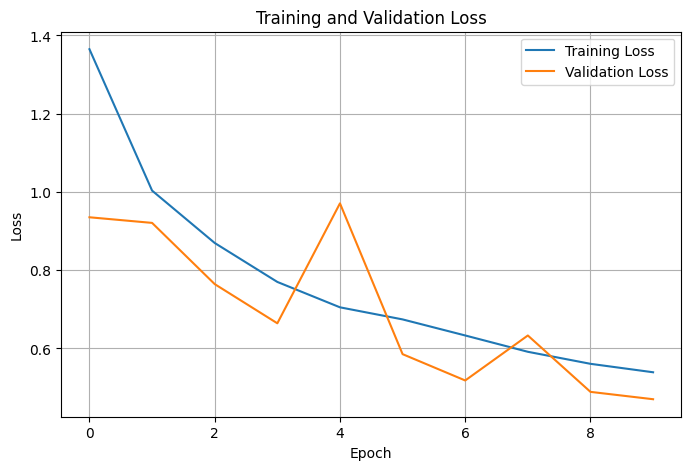

In [63]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

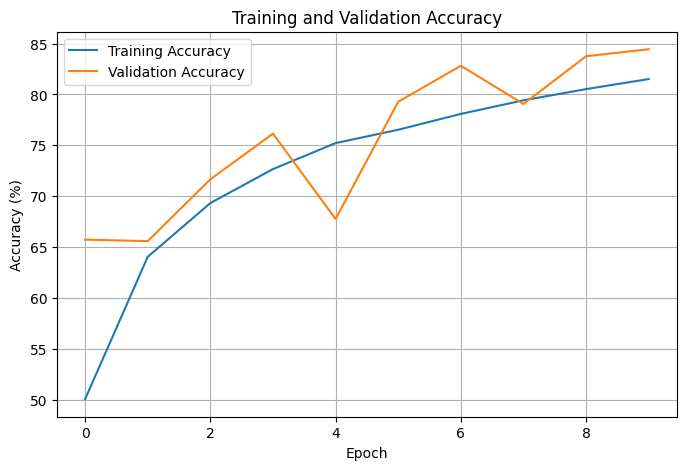

In [64]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

In [65]:
torch.save(
    model.state_dict(),
    "satellite_cnn.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [66]:
model = SatelliteCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [67]:
best_val_accuracy = 0.0

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

In [68]:
for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "best_satellite_cnn.pth"
        )

        print("  → Best model saved!")

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

  → Best model saved!
Epoch [1/10] | Train Loss: 1.4264 | Train Acc: 46.92% | Val Loss: 1.0409 | Val Acc: 63.11%
  → Best model saved!
Epoch [2/10] | Train Loss: 0.9882 | Train Acc: 64.94% | Val Loss: 0.9613 | Val Acc: 63.85%
  → Best model saved!
Epoch [3/10] | Train Loss: 0.8390 | Train Acc: 70.76% | Val Loss: 0.8706 | Val Acc: 68.86%
  → Best model saved!
Epoch [4/10] | Train Loss: 0.7601 | Train Acc: 73.20% | Val Loss: 0.7193 | Val Acc: 74.54%
  → Best model saved!
Epoch [5/10] | Train Loss: 0.7126 | Train Acc: 74.83% | Val Loss: 0.6114 | Val Acc: 77.68%
  → Best model saved!
Epoch [6/10] | Train Loss: 0.6645 | Train Acc: 76.84% | Val Loss: 0.5136 | Val Acc: 81.75%
Epoch [7/10] | Train Loss: 0.6383 | Train Acc: 77.94% | Val Loss: 0.5185 | Val Acc: 80.42%
  → Best model saved!
Epoch [8/10] | Train Loss: 0.5908 | Train Acc: 79.62% | Val Loss: 0.5199 | Val Acc: 82.69%
  → Best model saved!
Epoch [9/10] | Train Loss: 0.5711 | Train Acc: 80.21% | Val Loss: 0.4691 | Val Acc: 83.98%
Epoch

In [69]:
model.load_state_dict(
    torch.load(
        "best_satellite_cnn.pth",
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded!")

Best model loaded!


In [70]:
images, labels = next(iter(val_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)

predictions = outputs.argmax(dim=1)

print("Predictions:", predictions[:10].cpu().numpy())
print("Actual:     ", labels[:10].cpu().numpy())

Predictions: [3 1 4 5 2 4 5 8 8 8]
Actual:      [6 1 4 5 2 4 9 8 8 8]


In [71]:
# Stage 05
model = SatelliteCNN().to(device)

In [72]:
model.load_state_dict(
    torch.load(
        "best_satellite_cnn.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [73]:
def evaluate_model(model, loader, device):

    model.eval()

    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    accuracy = 100 * correct / total

    return accuracy, all_labels, all_predictions

In [74]:
test_accuracy, all_labels, all_predictions = evaluate_model(
    model,
    test_loader,
    device
)

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 83.33%


In [75]:
class_names = dataset.classes

print(class_names)

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [76]:
from sklearn.metrics import classification_report

In [77]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
)

print(report)

                      precision    recall  f1-score   support

          AnnualCrop       0.89      0.85      0.87       472
              Forest       0.88      0.95      0.92       442
HerbaceousVegetation       0.79      0.76      0.78       458
             Highway       0.84      0.54      0.66       391
          Industrial       0.94      0.87      0.91       378
             Pasture       0.85      0.79      0.82       299
       PermanentCrop       0.76      0.74      0.75       379
         Residential       0.79      1.00      0.88       450
               River       0.70      0.86      0.77       375
             SeaLake       0.95      0.92      0.93       406

            accuracy                           0.83      4050
           macro avg       0.84      0.83      0.83      4050
        weighted avg       0.84      0.83      0.83      4050



In [78]:
from sklearn.metrics import confusion_matrix

In [79]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

[[403   4   7   1   0  13  26   0  12   6]
 [  0 420   5   0   0   8   0   0   3   6]
 [  1   6 350  14   3   6  17  38  20   3]
 [ 16   0  18 213  11   5  30  28  70   0]
 [  0   0   1   3 330   0   0  44   0   0]
 [  4  23   7   2   0 235  13   0  12   3]
 [  7   1  53   9   5   3 282   8  11   0]
 [  0   0   0   0   0   0   0 449   1   0]
 [ 18   7   2  13   2   5   3   1 321   3]
 [  6  15   0   0   0   2   0   0  11 372]]


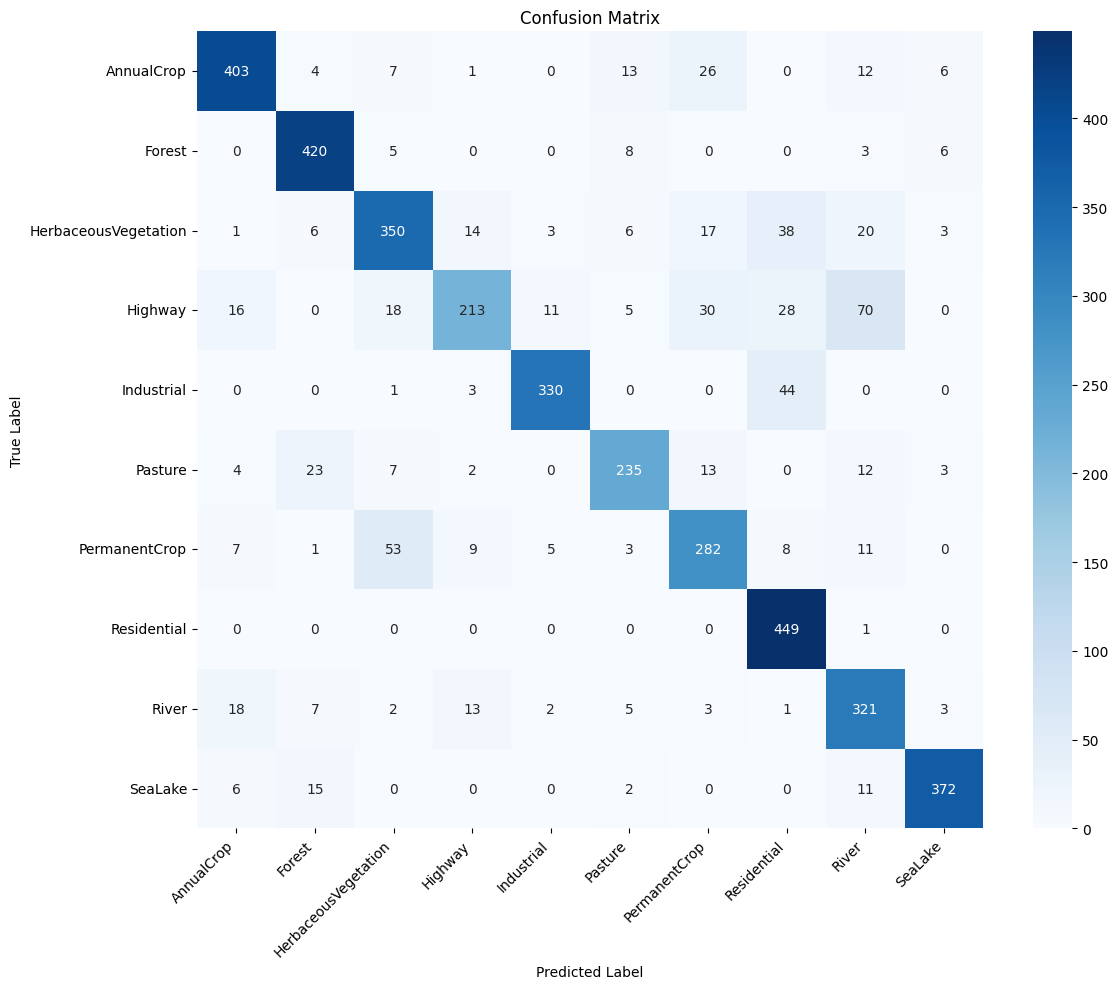

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [81]:
cm_without_diagonal = cm.copy()

np.fill_diagonal(
    cm_without_diagonal,
    0
)

In [82]:
confused_pairs = []

for i in range(len(class_names)):

    for j in range(len(class_names)):

        if i != j:

            confused_pairs.append(
                (
                    cm_without_diagonal[i, j],
                    class_names[i],
                    class_names[j]
                )
            )

confused_pairs.sort(
    reverse=True
)

print("Most common confusion pairs:\n")

for count, actual, predicted in confused_pairs[:10]:

    print(
        f"Actual: {actual:25} "
        f"→ Predicted: {predicted:25} "
        f"Count: {count}"
    )

Most common confusion pairs:

Actual: Highway                   → Predicted: River                     Count: 70
Actual: PermanentCrop             → Predicted: HerbaceousVegetation      Count: 53
Actual: Industrial                → Predicted: Residential               Count: 44
Actual: HerbaceousVegetation      → Predicted: Residential               Count: 38
Actual: Highway                   → Predicted: PermanentCrop             Count: 30
Actual: Highway                   → Predicted: Residential               Count: 28
Actual: AnnualCrop                → Predicted: PermanentCrop             Count: 26
Actual: Pasture                   → Predicted: Forest                    Count: 23
Actual: HerbaceousVegetation      → Predicted: River                     Count: 20
Actual: River                     → Predicted: AnnualCrop                Count: 18


In [83]:
def denormalize(image):

    image = image * 0.5 + 0.5

    return image.clamp(0, 1)

In [84]:
images, labels = next(iter(test_loader))

images_gpu = images.to(device)

with torch.no_grad():

    outputs = model(images_gpu)

    predictions = outputs.argmax(dim=1).cpu()

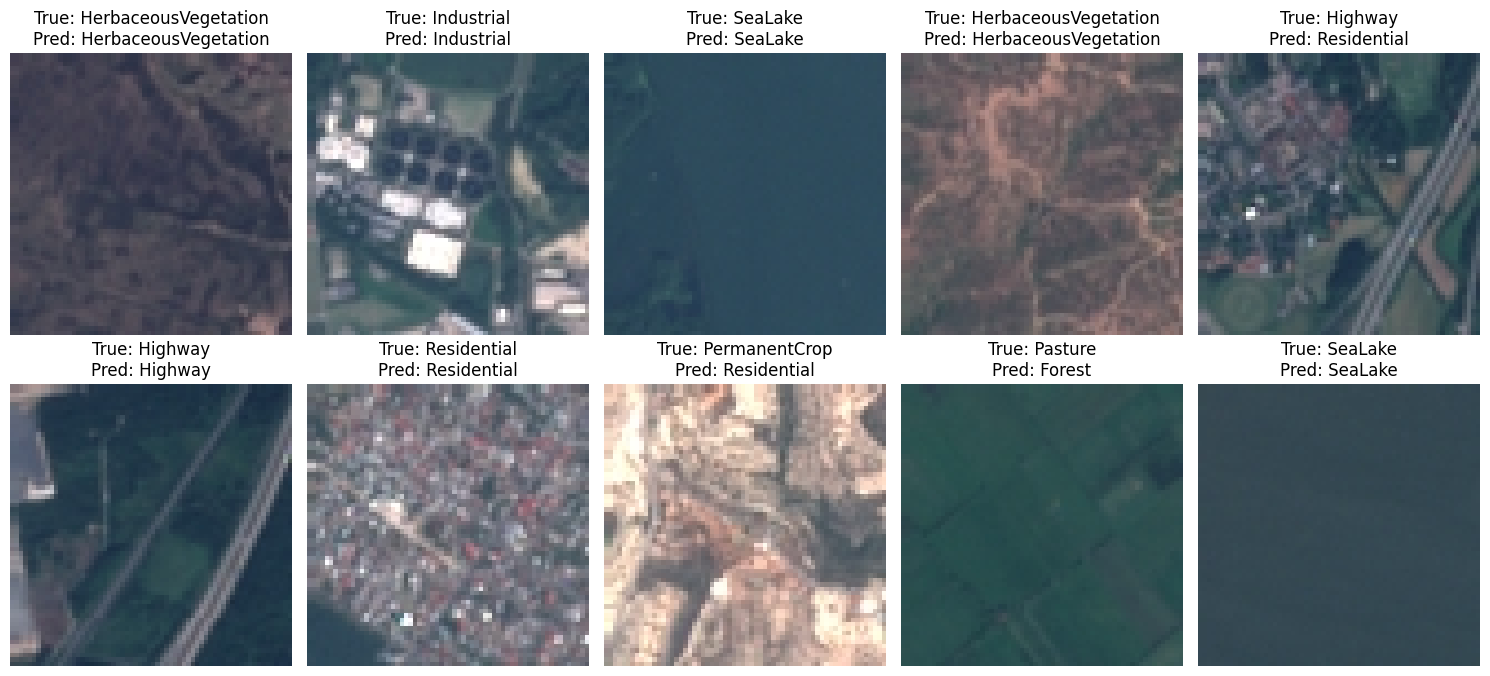

In [85]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flatten()):

    image = denormalize(images[i])

    ax.imshow(
        image.permute(1, 2, 0)
    )

    true_class = class_names[labels[i].item()]
    predicted_class = class_names[predictions[i].item()]

    ax.set_title(
        f"True: {true_class}\nPred: {predicted_class}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [86]:
incorrect_indices = []

for i in range(len(labels)):

    if predictions[i] != labels[i]:

        incorrect_indices.append(i)

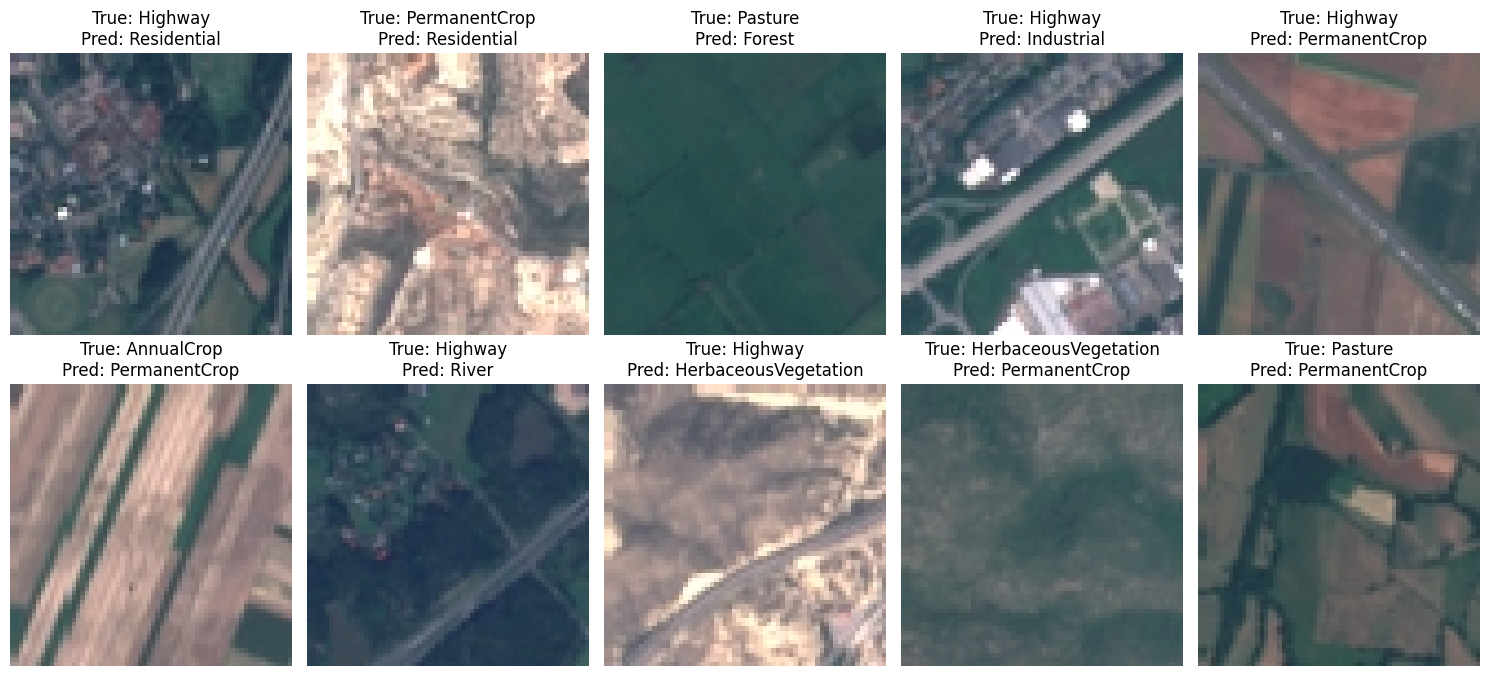

In [87]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 7)
)

for ax, i in zip(
    axes.flatten(),
    incorrect_indices[:10]
):

    image = denormalize(images[i])

    ax.imshow(
        image.permute(1, 2, 0)
    )

    true_class = class_names[
        labels[i].item()
    ]

    predicted_class = class_names[
        predictions[i].item()
    ]

    ax.set_title(
        f"True: {true_class}\n"
        f"Pred: {predicted_class}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [88]:
results = {
    "Test Accuracy": test_accuracy
}

results

{'Test Accuracy': 83.33333333333333}

In [89]:
with open("evaluation_results.txt", "w") as f:

    f.write(
        f"Test Accuracy: {test_accuracy:.2f}%\n\n"
    )

    f.write(report)

In [90]:
# Stage 06
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(
        64,
        scale=(0.8, 1.0)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [91]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomVerticalFlip(p=0.5),

    transforms.RandomRotation(20),

    transforms.RandomResizedCrop(
        size=64,
        scale=(0.8, 1.0)
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [92]:
val_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [93]:
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [94]:
train_full = datasets.ImageFolder(
    root=dataset_path,
    transform=train_transform
)

val_full = datasets.ImageFolder(
    root=dataset_path,
    transform=val_transform
)

test_full = datasets.ImageFolder(
    root=dataset_path,
    transform=test_transform
)

In [95]:
train_dataset = Subset(
    train_full,
    train_indices
)

val_dataset = Subset(
    val_full,
    val_indices
)

test_dataset = Subset(
    test_full,
    test_indices
)

In [96]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [97]:
class ImprovedSatelliteCNN(nn.Module):

    def __init__(self, num_classes=10):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128 * 8 * 8,
                256
            ),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(
                256,
                num_classes
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [98]:
model = ImprovedSatelliteCNN().to(device)

print(model)

ImprovedSatelliteCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): BatchNorm1d

In [99]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("Input:", images.shape)
print("Output:", outputs.shape)

Input: torch.Size([64, 3, 64, 64])
Output: torch.Size([64, 10])


In [100]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 2194186
Trainable parameters: 2194186


In [101]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [102]:
criterion = nn.CrossEntropyLoss()

In [103]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [104]:
NUM_EPOCHS = 20
PATIENCE = 5

In [105]:
best_val_accuracy = 0.0
epochs_without_improvement = 0

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

In [106]:
for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # Update learning rate
    scheduler.step(val_accuracy)

    # Current learning rate
    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}% "
        f"| LR: {current_lr:.6f}"
    )

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            "best_improved_satellite_cnn.pth"
        )

        print("  → Best improved model saved!")

    else:

        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch + 1}"
        )

        break

Epoch [1/20] | Train Loss: 1.0675 | Train Acc: 61.85% | Val Loss: 0.8532 | Val Acc: 68.77% | LR: 0.001000
  → Best improved model saved!
Epoch [2/20] | Train Loss: 0.7929 | Train Acc: 72.02% | Val Loss: 0.6838 | Val Acc: 76.54% | LR: 0.001000
  → Best improved model saved!
Epoch [3/20] | Train Loss: 0.6828 | Train Acc: 75.98% | Val Loss: 0.5974 | Val Acc: 78.89% | LR: 0.001000
  → Best improved model saved!
Epoch [4/20] | Train Loss: 0.6086 | Train Acc: 78.66% | Val Loss: 1.3716 | Val Acc: 57.14% | LR: 0.001000
Epoch [5/20] | Train Loss: 0.5923 | Train Acc: 79.17% | Val Loss: 1.1545 | Val Acc: 62.02% | LR: 0.001000
Epoch [6/20] | Train Loss: 0.5134 | Train Acc: 81.74% | Val Loss: 0.6946 | Val Acc: 76.59% | LR: 0.000500
Epoch [7/20] | Train Loss: 0.4388 | Train Acc: 84.78% | Val Loss: 0.3977 | Val Acc: 86.47% | LR: 0.000500
  → Best improved model saved!
Epoch [8/20] | Train Loss: 0.4106 | Train Acc: 85.29% | Val Loss: 0.3790 | Val Acc: 86.94% | LR: 0.000500
  → Best improved model save

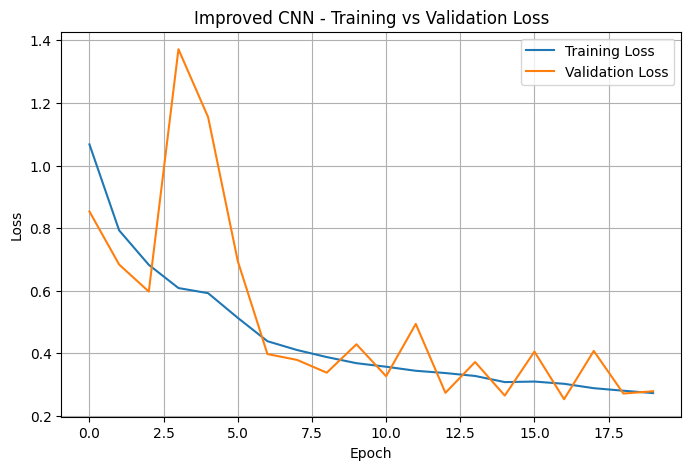

In [107]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Improved CNN - Training vs Validation Loss"
)

plt.legend()
plt.grid()

plt.show()

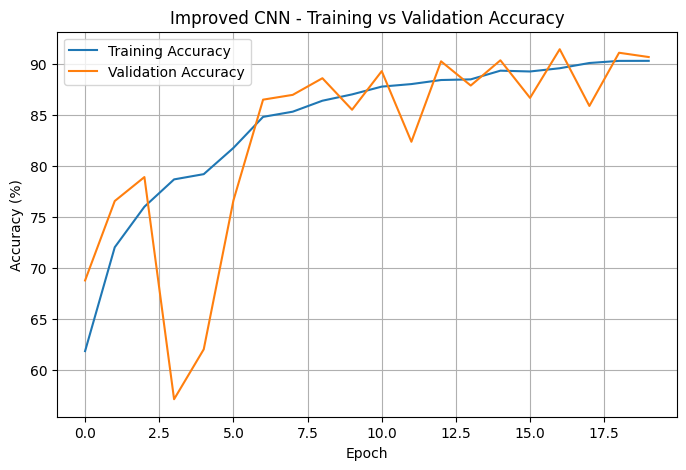

In [108]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "Improved CNN - Training vs Validation Accuracy"
)

plt.legend()
plt.grid()

plt.show()

In [109]:
model.load_state_dict(
    torch.load(
        "best_improved_satellite_cnn.pth",
        map_location=device
    )
)

model.eval()

print("Best improved model loaded.")

Best improved model loaded.


In [110]:
improved_test_accuracy, improved_labels, improved_predictions = evaluate_model(
    model,
    test_loader,
    device
)

print(
    f"Improved CNN Test Accuracy: "
    f"{improved_test_accuracy:.2f}%"
)

Improved CNN Test Accuracy: 90.79%


In [111]:
print("Model Comparison")
print("----------------------------")

print(
    f"Baseline CNN:  {test_accuracy:.2f}%"
)

print(
    f"Improved CNN:  {improved_test_accuracy:.2f}%"
)

print(
    f"Difference:    "
    f"{improved_test_accuracy - test_accuracy:+.2f}%"
)

Model Comparison
----------------------------
Baseline CNN:  83.33%
Improved CNN:  90.79%
Difference:    +7.46%


In [112]:
print("Baseline CNN")
print("=" * 70)

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names
    )
)

Baseline CNN
                      precision    recall  f1-score   support

          AnnualCrop       0.89      0.85      0.87       472
              Forest       0.88      0.95      0.92       442
HerbaceousVegetation       0.79      0.76      0.78       458
             Highway       0.84      0.54      0.66       391
          Industrial       0.94      0.87      0.91       378
             Pasture       0.85      0.79      0.82       299
       PermanentCrop       0.76      0.74      0.75       379
         Residential       0.79      1.00      0.88       450
               River       0.70      0.86      0.77       375
             SeaLake       0.95      0.92      0.93       406

            accuracy                           0.83      4050
           macro avg       0.84      0.83      0.83      4050
        weighted avg       0.84      0.83      0.83      4050



In [113]:
print("Improved CNN")
print("=" * 70)

print(
    classification_report(
        improved_labels,
        improved_predictions,
        target_names=class_names
    )
)

Improved CNN
                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.89      0.93       472
              Forest       0.97      0.97      0.97       442
HerbaceousVegetation       0.87      0.85      0.86       458
             Highway       0.93      0.87      0.90       391
          Industrial       0.96      0.85      0.90       378
             Pasture       0.92      0.96      0.94       299
       PermanentCrop       0.91      0.76      0.83       379
         Residential       0.79      1.00      0.88       450
               River       0.86      0.94      0.90       375
             SeaLake       0.97      0.98      0.97       406

            accuracy                           0.91      4050
           macro avg       0.91      0.91      0.91      4050
        weighted avg       0.91      0.91      0.91      4050



In [114]:
improved_cm = confusion_matrix(
    improved_labels,
    improved_predictions
)

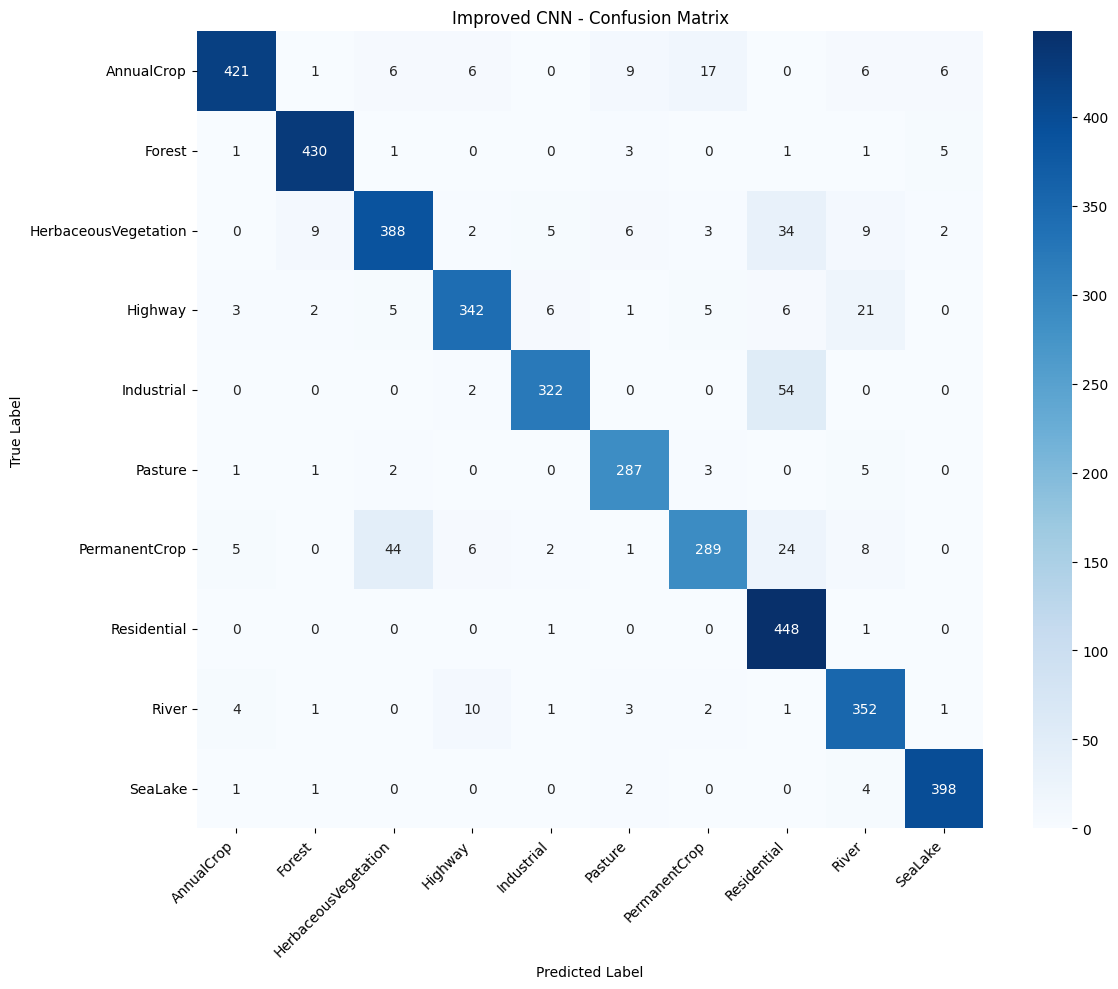

In [115]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    improved_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "Improved CNN - Confusion Matrix"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [116]:
# Stage 07
from torchvision import models

In [117]:
resnet = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


In [118]:
print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [119]:
print(resnet.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [120]:
resnet.fc = nn.Linear(
    resnet.fc.in_features,
    10
)

In [121]:
print(resnet.fc)

Linear(in_features=512, out_features=10, bias=True)


In [122]:
resnet = resnet.to(device)

In [123]:
print(device)

cuda


In [124]:
mean = [0.5, 0.5, 0.5]
std  = [0.5, 0.5, 0.5]

In [125]:
weights = models.ResNet18_Weights.DEFAULT

In [126]:
print(weights.transforms())

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [127]:
resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomVerticalFlip(p=0.5),

    transforms.RandomRotation(20),

    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0)
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [128]:
resnet_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [129]:
resnet_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [130]:
resnet_train_full = datasets.ImageFolder(
    root=dataset_path,
    transform=resnet_train_transform
)

resnet_val_full = datasets.ImageFolder(
    root=dataset_path,
    transform=resnet_val_transform
)

resnet_test_full = datasets.ImageFolder(
    root=dataset_path,
    transform=resnet_test_transform
)

In [131]:
resnet_train_dataset = Subset(
    resnet_train_full,
    train_indices
)

resnet_val_dataset = Subset(
    resnet_val_full,
    val_indices
)

resnet_test_dataset = Subset(
    resnet_test_full,
    test_indices
)

In [132]:
resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [133]:
images, labels = next(
    iter(resnet_train_loader)
)

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])


In [134]:
images = images.to(device)

outputs = resnet(images)

print("Output:", outputs.shape)

Output: torch.Size([32, 10])


In [135]:
for param in resnet.parameters():
    param.requires_grad = False

In [136]:
for param in resnet.fc.parameters():
    param.requires_grad = True

In [137]:
trainable_params = sum(
    p.numel()
    for p in resnet.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in resnet.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 11181642
Trainable parameters: 5130


In [138]:
criterion = nn.CrossEntropyLoss()

In [139]:
optimizer = torch.optim.AdamW(
    resnet.fc.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [140]:
NUM_EPOCHS = 5

resnet_train_losses = []
resnet_train_accuracies = []

resnet_val_losses = []
resnet_val_accuracies = []

best_resnet_val_accuracy = 0.0

In [141]:
for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        resnet,
        resnet_train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate(
        resnet,
        resnet_val_loader,
        criterion,
        device
    )

    resnet_train_losses.append(train_loss)
    resnet_train_accuracies.append(train_accuracy)

    resnet_val_losses.append(val_loss)
    resnet_val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_resnet_val_accuracy:

        best_resnet_val_accuracy = val_accuracy

        torch.save(
            resnet.state_dict(),
            "resnet18_feature_extractor.pth"
        )

        print("  → Best ResNet model saved!")

Epoch [1/5] | Train Loss: 0.7742 | Train Acc: 76.33% | Val Loss: 0.4083 | Val Acc: 87.09%
  → Best ResNet model saved!
Epoch [2/5] | Train Loss: 0.4622 | Train Acc: 84.79% | Val Loss: 0.3297 | Val Acc: 89.04%
  → Best ResNet model saved!
Epoch [3/5] | Train Loss: 0.4138 | Train Acc: 85.90% | Val Loss: 0.3090 | Val Acc: 89.38%
  → Best ResNet model saved!
Epoch [4/5] | Train Loss: 0.3905 | Train Acc: 86.69% | Val Loss: 0.2805 | Val Acc: 89.85%
  → Best ResNet model saved!
Epoch [5/5] | Train Loss: 0.3742 | Train Acc: 87.43% | Val Loss: 0.2917 | Val Acc: 89.70%


In [142]:
resnet.load_state_dict(
    torch.load(
        "resnet18_feature_extractor.pth",
        map_location=device
    )
)

resnet.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [143]:
resnet_test_accuracy, resnet_labels, resnet_predictions = evaluate_model(
    resnet,
    resnet_test_loader,
    device
)

print(
    f"ResNet18 Feature Extraction "
    f"Test Accuracy: {resnet_test_accuracy:.2f}%"
)

ResNet18 Feature Extraction Test Accuracy: 89.73%


In [144]:
# Fine tuning
resnet_ft = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

In [145]:
resnet_ft.fc = nn.Linear(
    resnet_ft.fc.in_features,
    10
)

In [146]:
resnet_ft = resnet_ft.to(device)

In [147]:
for param in resnet_ft.parameters():
    param.requires_grad = False

In [148]:
for param in resnet_ft.layer4.parameters():
    param.requires_grad = True

for param in resnet_ft.fc.parameters():
    param.requires_grad = True

In [149]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        resnet_ft.parameters()
    ),
    lr=0.0001,
    weight_decay=1e-4
)

In [150]:
NUM_EPOCHS = 8

best_ft_val_accuracy = 0.0

ft_train_losses = []
ft_train_accuracies = []

ft_val_losses = []
ft_val_accuracies = []

In [151]:
from google.colab import drive
import os

drive.mount("/content/drive")

MODEL_DIR = "/content/drive/MyDrive/Satellite_Image_Classification/models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_resnet18_finetuned.pth"
)

print("Model save path:", BEST_MODEL_PATH)


Mounted at /content/drive
Model save path: /content/drive/MyDrive/Satellite_Image_Classification/models/best_resnet18_finetuned.pth


In [152]:
for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        resnet_ft,
        resnet_train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate(
        resnet_ft,
        resnet_val_loader,
        criterion,
        device
    )

    ft_train_losses.append(train_loss)
    ft_train_accuracies.append(train_accuracy)

    ft_val_losses.append(val_loss)
    ft_val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_ft_val_accuracy:

        best_ft_val_accuracy = val_accuracy

        torch.save(
        resnet_ft.state_dict(),
        BEST_MODEL_PATH
        )

        print("Best model saved to Google Drive!")

        #print("  → Best fine-tuned ResNet saved!")

Epoch [1/8] | Train Loss: 0.3057 | Train Acc: 90.07% | Val Loss: 0.1277 | Val Acc: 95.88%
Best model saved to Google Drive!
Epoch [2/8] | Train Loss: 0.1657 | Train Acc: 94.34% | Val Loss: 0.0961 | Val Acc: 96.84%
Best model saved to Google Drive!
Epoch [3/8] | Train Loss: 0.1364 | Train Acc: 95.32% | Val Loss: 0.0928 | Val Acc: 97.11%
Best model saved to Google Drive!
Epoch [4/8] | Train Loss: 0.1261 | Train Acc: 95.71% | Val Loss: 0.1150 | Val Acc: 95.95%
Epoch [5/8] | Train Loss: 0.1083 | Train Acc: 96.31% | Val Loss: 0.0747 | Val Acc: 97.83%
Best model saved to Google Drive!
Epoch [6/8] | Train Loss: 0.1016 | Train Acc: 96.50% | Val Loss: 0.0685 | Val Acc: 97.51%
Epoch [7/8] | Train Loss: 0.0951 | Train Acc: 96.78% | Val Loss: 0.0806 | Val Acc: 97.38%
Epoch [8/8] | Train Loss: 0.0939 | Train Acc: 96.77% | Val Loss: 0.0937 | Val Acc: 97.14%


In [155]:
from google.colab import drive
import os

drive.mount("/content/drive")

MODEL_PATH = "/content/drive/MyDrive/Satellite_Image_Classification/models/best_resnet18_finetuned.pth"

print("Model exists:", os.path.exists(MODEL_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model exists: True


In [156]:
resnet_ft.load_state_dict(
    torch.load(
        #"best_resnet18_finetuned.pth",
        MODEL_PATH,
        map_location=device
    )
)

resnet_ft.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [157]:
ft_test_accuracy, ft_labels, ft_predictions = evaluate_model(
    resnet_ft,
    resnet_test_loader,
    device
)

print(
    f"Fine-tuned ResNet18 "
    f"Test Accuracy: {ft_test_accuracy:.2f}%"
)

Fine-tuned ResNet18 Test Accuracy: 96.86%


In [158]:
print("=" * 50)
print("MODEL COMPARISON")
print("=" * 50)

print(
    f"Baseline CNN:          {test_accuracy:.2f}%"
)

print(
    f"Improved CNN:          {improved_test_accuracy:.2f}%"
)

print(
    f"ResNet18 Feature:      {resnet_test_accuracy:.2f}%"
)

print(
    f"ResNet18 Fine-tuned:   {ft_test_accuracy:.2f}%"
)

MODEL COMPARISON
Baseline CNN:          83.33%
Improved CNN:          90.79%
ResNet18 Feature:      89.73%
ResNet18 Fine-tuned:   96.86%


In [159]:
print(
    classification_report(
        ft_labels,
        ft_predictions,
        target_names=class_names
    )
)

                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.95      0.96       472
              Forest       0.95      1.00      0.97       442
HerbaceousVegetation       0.99      0.90      0.94       458
             Highway       0.96      0.97      0.96       391
          Industrial       0.99      0.98      0.98       378
             Pasture       0.97      0.98      0.97       299
       PermanentCrop       0.91      0.97      0.94       379
         Residential       0.99      1.00      0.99       450
               River       0.97      0.96      0.97       375
             SeaLake       0.99      0.99      0.99       406

            accuracy                           0.97      4050
           macro avg       0.97      0.97      0.97      4050
        weighted avg       0.97      0.97      0.97      4050



In [160]:
ft_cm = confusion_matrix(
    ft_labels,
    ft_predictions
)

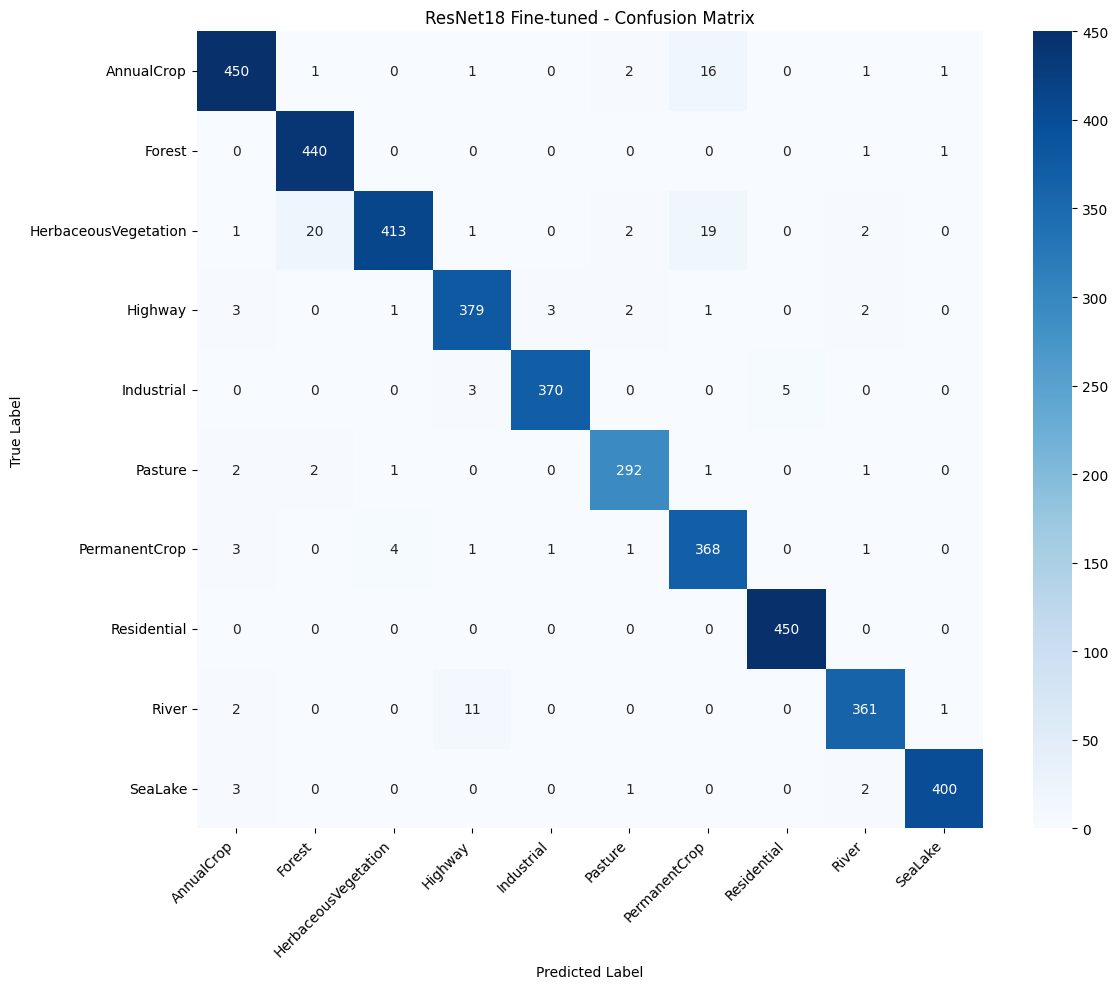

In [161]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    ft_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "ResNet18 Fine-tuned - Confusion Matrix"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [162]:
# Stage 8
import torch
import torch.nn as nn
from torchvision import models, transforms

In [163]:
class_names = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
]

In [164]:
model = models.resnet18(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    10
)

In [166]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.load_state_dict(
    torch.load(
        # "best_resnet18_finetuned.pth",
        MODEL_PATH,
        map_location=device
    )
)

model = model.to(device)

model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [167]:
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [168]:
def predict_image(image):

    # Apply preprocessing
    image_tensor = inference_transform(image)

    # Add batch dimension
    image_tensor = image_tensor.unsqueeze(0)

    # Move to device
    image_tensor = image_tensor.to(device)

    # Disable gradients
    with torch.no_grad():

        # Model prediction
        outputs = model(image_tensor)

        # Convert logits to probabilities
        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        # Highest probability
        confidence, predicted_idx = torch.max(
            probabilities,
            dim=1
        )

    predicted_class = class_names[
        predicted_idx.item()
    ]

    confidence = confidence.item()

    return predicted_class, confidence, probabilities

In [169]:
test_image_path, true_label = resnet_test_full.samples[
    test_indices[0]
]

print("Image:", test_image_path)
print("True class:", class_names[true_label])

Image: /content/EuroSAT_RGB/HerbaceousVegetation/HerbaceousVegetation_1740.jpg
True class: HerbaceousVegetation


In [170]:
from PIL import Image

image = Image.open(
    test_image_path
).convert("RGB")

print(image.size)

(64, 64)


In [171]:
predicted_class, confidence, probabilities = predict_image(
    image
)

print("True class:", class_names[true_label])
print("Predicted:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

True class: HerbaceousVegetation
Predicted: HerbaceousVegetation
Confidence: 99.49%


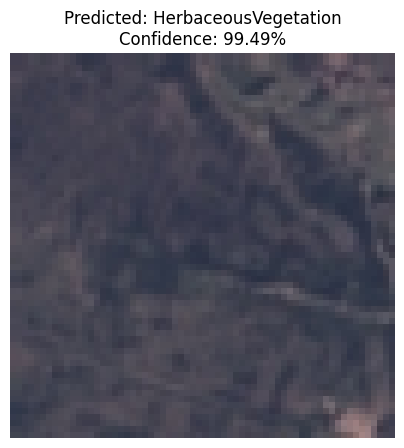

In [172]:
plt.figure(figsize=(5, 5))

plt.imshow(image)

plt.title(
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%"
)

plt.axis("off")

plt.show()

In [173]:
probabilities = probabilities.squeeze().cpu().numpy()

for class_name, probability in zip(
    class_names,
    probabilities
):

    print(
        f"{class_name:25} "
        f"{probability * 100:.2f}%"
    )

AnnualCrop                0.00%
Forest                    0.21%
HerbaceousVegetation      99.49%
Highway                   0.00%
Industrial                0.00%
Pasture                   0.09%
PermanentCrop             0.12%
Residential               0.08%
River                     0.00%
SeaLake                   0.01%


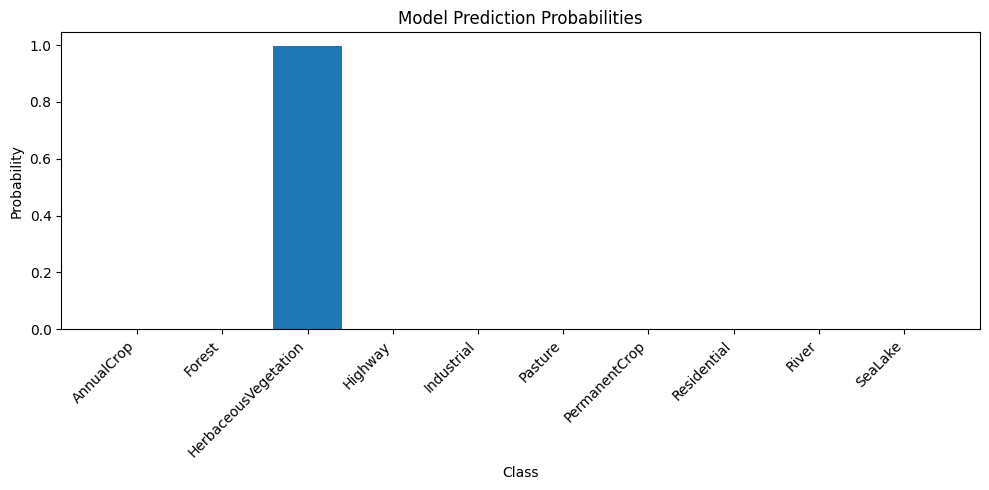

In [174]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_names,
    probabilities
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("Probability")
plt.xlabel("Class")
plt.title("Model Prediction Probabilities")

plt.tight_layout()
plt.show()

In [175]:
top_probs, top_indices = torch.topk(
    probabilities_tensor := torch.tensor(probabilities),
    3
)

for probability, index in zip(
    top_probs,
    top_indices
):

    print(
        f"{class_names[index.item()]}: "
        f"{probability.item() * 100:.2f}%"
    )

HerbaceousVegetation: 99.49%
Forest: 0.21%
PermanentCrop: 0.12%


In [176]:
print("Model architecture:")
print(resnet_ft)

print("\nModel device:", next(resnet_ft.parameters()).device)
print("Model is in evaluation mode:", not resnet_ft.training)

Model architecture:
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): R